# 08 — Visualization and dual-pol RGB composite

**Goal:** display GCOV values in a way that can be read: dB scale, robust stretch (2–98 %
percentiles), and a dual-pol colour composite.

Quad-pol data are usually shown as a Pauli RGB. With dual-pol HH/HV the common composite is
**R = HH, G = HV, B = HH/HV**: forests (strong volume, high HV) look green, bare or smooth surfaces
(low HV, high ratio) look blue/purple, buildings (strong HH) red/pink.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "08"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency", "aoi_bounds"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])
from nisar_s1.polarimetry import to_db, dualpol_rgb, stretch
import geopandas as gpd

In [2]:
with src_ctx() as h5:
    prof = P.product_profile(h5)
    grid = prof.grids[session["frequency"]]
    win = P.window_from_bounds(grid, session["aoi_bounds"])
    hh = P.read_layer(h5, grid, "HHHH", win)
    hv = P.read_layer(h5, grid, "HVHV", win)
x0, y0 = win.transform.c, win.transform.f
ext = [x0, x0 + win.transform.a * win.shape[1], y0 + win.transform.e * win.shape[0], y0]
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(grid.epsg)

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5


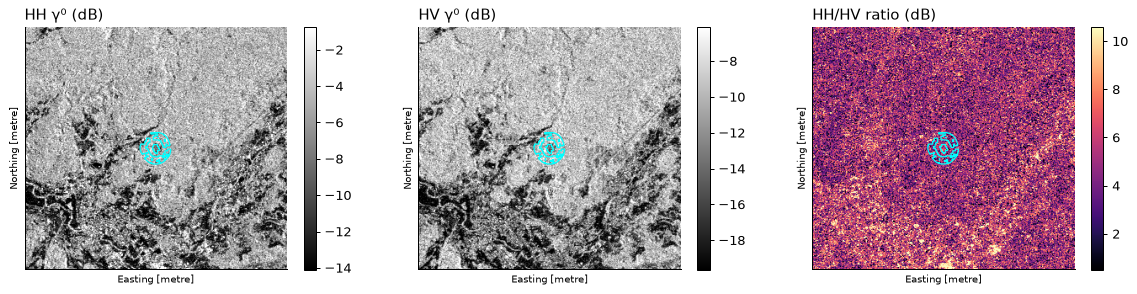

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, (a, t, cm) in zip(axs, [(to_db(hh), "HH γ⁰ (dB)", "gray"), (to_db(hv), "HV γ⁰ (dB)", "gray"),
                                (to_db(hh) - to_db(hv), "HH/HV ratio (dB)", "magma")]):
    lo, hi = np.nanpercentile(a, [2, 98])
    im = ax.imshow(a, cmap=cm, vmin=lo, vmax=hi, extent=ext)
    sites.boundary.plot(ax=ax, color="cyan", lw=1)
    ax.set_title(t, loc="left"); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, shrink=0.7)
fig.savefig(OUT / "08_channels.png", dpi=110, bbox_inches="tight"); plt.show()

## Dual-pol RGB

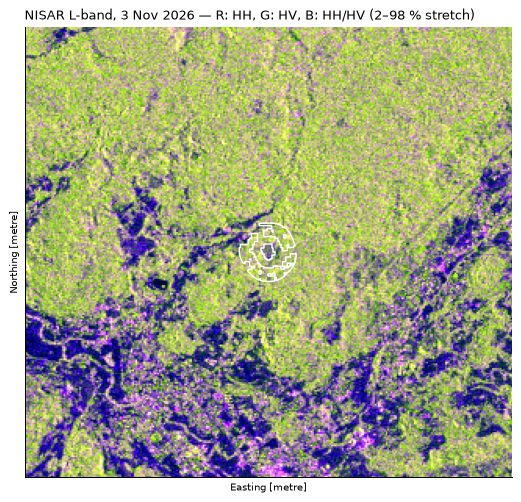

In [4]:
rgb = dualpol_rgb(hh, hv)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(rgb, extent=ext)
sites.boundary.plot(ax=ax, color="white", lw=1.2)
ax.set_title("NISAR L-band, 3 Nov 2026 — R: HH, G: HV, B: HH/HV (2–98 % stretch)", loc="left", fontsize=10)
ax.set_xticks([]); ax.set_yticks([])
fig.savefig(OUT / "08_rgb.png", dpi=130, bbox_inches="tight"); plt.show()

**Reading the composite:** the forested Vosges slopes are green (HV volume scattering); meadows and
the clear-cut are darker/bluer (less HV); villages appear pink (double bounce in HH). The same
stretch must be used when comparing two dates — otherwise colours change because of the stretch,
not of the ground.

In [5]:
checks = {
    "RGB in [0, 1]": rgb.min() >= 0 and rgb.max() <= 1,
    "figure written": (OUT / "08_rgb.png").exists(),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 08 STATUS: PASS")

  [x] RGB in [0, 1]
  [x] figure written
Module 08 STATUS: PASS
